# Notebook Name: 02_eda_and_statistics.ipynb

## Objectives
* Perform Exploratory Data Analysis (EDA) on the processed dataset (`cleaned_diabetic_data.csv`).
* Calculate comprehensive descriptive statistics (Mean, Median, Standard Deviation, IQR) segmented by 30-day readmission status.
* Examine distributions and cross-tabulations of key demographic and clinical features.
* Generate high-resolution, publication-ready data visualizations (Boxplots, Bar Charts, Histograms) saved to `docs/visualizations/`.
* Deliver data storytelling narratives linking statistical findings to hospital operational insights.

## Inputs
* `data/processed/cleaned_diabetic_data.csv`: Cleaned dataset with 69,990 unique patient records and binary target `readmitted_30`.

## Outputs
* Summary statistics tables displayed inline.
* `docs/visualizations/length_of_stay_vs_readmission.png`: Visualizing hospital stay duration against readmission risk.
* `docs/visualizations/inpatient_visits_vs_readmission.png`: Visualizing prior inpatient history impact on readmission rate.

## Additional Comments
* Descriptive statistics cover both central tendency (Mean, Median) and dispersion (Standard Deviation, Interquartile Range) as required by Code Institute assessment guidelines.

## The Pipeline
1. **Executive Overview**
2. **Data Import & Environment Setup**
3. **Descriptive Statistics Breakdown**
4. **Demographic & Clinical Distribution Analysis**
5. **Key Visualizations & Data Storytelling**
6. **Preparation Summary**
7. **Version Control Workflow**
8. **Next Step**
9. **Acknowledgements and Credits**
10. **Sources and Layout Inspiration**
11. **Tooling and Assistance**

## Executive Overview

This notebook carries out the Exploratory Data Analysis (EDA) phase of analytical pipeline. By evaluating central tendencies, dispersion metrics, and feature relationships against 30-day readmission outcomes (`readmitted_30`), I established baseline clinical patterns and identified high-risk patient segments to inform machine learning feature selection and dashboard architecture.

## Data Import & Environment Setup

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

# Load clean processed dataset
df = pd.read_csv('../data/processed/cleaned_diabetic_data.csv')

print(f"Processed dataset successfully loaded for EDA.")
print(f"Total Patient Records: {df.shape[0]} | Total Features: {df.shape[1]}\n")

# Preview first 5 rows
display(df.head(5))

Processed dataset successfully loaded for EDA.
Total Patient Records: 69990 | Total Features: 47



,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmitted_30
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,Unknown,...,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,...,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,Unknown,...,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,Unknown,...,Steady,No,No,No,No,No,Ch,Yes,NO,0


## Descriptive Statistics Breakdown

To comply with the Code Institute handbook criteria for statistical analysis, I evaluated measures of central tendency (Mean, Median) and measures of dispersion (Standard Deviation, Interquartile Range - IQR) across primary continuous clinical features.

I segmented these statistics by our target variable (`readmitted_30`) to isolate differences between patients readmitted within 30 days (`1`) and those not readmitted early (`0`).

In [6]:
# Core numerical features for descriptive analysis
numeric_cols = [
    'time_in_hospital', 
    'num_lab_procedures', 
    'num_procedures', 
    'num_medications', 
    'number_outpatient', 
    'number_emergency', 
    'number_inpatient', 
    'number_diagnoses'
]

# Calculate Mean, Median, Standard Deviation, and Interquartile Range (IQR)
stats_records = []

for col in numeric_cols:
    for group in [0, 1]:
        sub = df[df['readmitted_30'] == group][col]
        
        q25 = sub.quantile(0.25)
        q75 = sub.quantile(0.75)
        iqr_val = q75 - q25
        
        stats_records.append({
            'Feature': col,
            '30-Day Readmission': 'Yes (<30d)' if group == 1 else 'No / >30d',
            'Mean': round(sub.mean(), 2),
            'Median': round(sub.median(), 2),
            'Std Dev': round(sub.std(), 2),
            'IQR': round(iqr_val, 2)
        })

stats_summary_df = pd.DataFrame(stats_records)

print("=== DESCRIPTIVE STATISTICS TABLE ===")
display(stats_summary_df)

=== DESCRIPTIVE STATISTICS TABLE ===


,Feature,30-Day Readmission,Mean,Median,Std Dev,IQR
0,time_in_hospital,No / >30d,4.22,3.0,2.92,4.0
1,time_in_hospital,Yes (<30d),4.79,4.0,3.06,5.0
2,num_lab_procedures,No / >30d,42.68,44.0,19.94,26.0
3,num_lab_procedures,Yes (<30d),44.91,46.0,19.34,25.0
4,num_procedures,No / >30d,1.43,1.0,1.76,2.0
5,num_procedures,Yes (<30d),1.42,1.0,1.73,2.0
6,num_medications,No / >30d,15.57,14.0,8.28,10.0
7,num_medications,Yes (<30d),16.62,15.0,8.32,10.0
8,number_outpatient,No / >30d,0.28,0.0,1.07,0.0
9,number_outpatient,Yes (<30d),0.31,0.0,1.05,0.0


##  Demographic & Clinical Distribution Analysis

I analyzed the categorical features across key demographic groups (Age, Gender, Race) and clinical management indicators (A1C testing results, Diabetes Medication Changes). 

Cross-tabulating these variables against 30-day readmission status helped me to spot patterns across patient subgroups and ensured the model considers meaningful clinical signals.

In [7]:
# Set primary demographic and clinical categorical variables
cat_features = ['age', 'race', 'gender', 'A1Cresult', 'change', 'diabetesMed']

print("=== DEMOGRAPHIC & CLINICAL READMISSION RATES ===")

for col in cat_features:
    print(f"\n--- Readmission Breakdown by {col.upper()} ---")
    
    # Calculate counts and percentage readmitted within 30 days
    crosstab = pd.crosstab(df[col], df['readmitted_30'], margins=True, margins_name='Total')
    crosstab['Readmit_Rate_%'] = (crosstab[1] / crosstab['Total'] * 100).round(2)
    
    # Rename columns for clarity
    crosstab.columns = ['Not Readmitted (0)', 'Readmitted <30d (1)', 'Total Encounters', 'Readmit Rate (%)']
    display(crosstab)

=== DEMOGRAPHIC & CLINICAL READMISSION RATES ===

--- Readmission Breakdown by AGE ---


,Not Readmitted (0),Readmitted <30d (1),Total Encounters,Readmit Rate (%)
age,,,,
[0-10),150,3,153,1.96
[10-20),508,26,534,4.87
[20-30),1038,83,1121,7.40
[30-40),2504,188,2692,6.98
[40-50),6322,506,6828,7.41
[50-60),11471,880,12351,7.12
[60-70),14274,1415,15689,9.02
[70-80),15934,1817,17751,10.24
[80-90),9911,1199,11110,10.79



--- Readmission Breakdown by RACE ---


,Not Readmitted (0),Readmitted <30d (1),Total Encounters,Readmit Rate (%)
race,,,,
AfricanAmerican,11532,1095,12627,8.67
Asian,447,41,488,8.40
Caucasian,47498,4807,52305,9.19
Hispanic,1379,122,1501,8.13
Other,1071,79,1150,6.87
Unknown,1778,141,1919,7.35
Total,63705,6285,69990,8.98



--- Readmission Breakdown by GENDER ---


...

,Not Readmitted (0),Readmitted <30d (1),Total Encounters,Readmit Rate (%)
A1Cresult,,,,
>7,2619,247,2866,8.62
>8,5730,509,6239,8.16
Norm,3418,323,3741,8.63
Total,11767,1079,12846,8.40



--- Readmission Breakdown by CHANGE ---


,Not Readmitted (0),Readmitted <30d (1),Total Encounters,Readmit Rate (%)
change,,,,
Ch,28524,2973,31497,9.44
No,35181,3312,38493,8.60
Total,63705,6285,69990,8.98



--- Readmission Breakdown by DIABETESMED ---


,Not Readmitted (0),Readmitted <30d (1),Total Encounters,Readmit Rate (%)
diabetesMed,,,,
No,15424,1262,16686,7.56
Yes,48281,5023,53304,9.42
Total,63705,6285,69990,8.98


## Visualizations & Data Storytelling

I constructed two distinct visual charts to communicate the primary clinical findings:
1. **Length of Stay Box Plot (`time_in_hospital`):** Illustrates the distribution, median, and spread of hospital stay durations across readmission categories.
2. **Prior Inpatient Visits Bar Chart (`number_inpatient`):** Demonstrates how prior hospital visit frequency dramatically escalates 30-day readmission risk.

Both charts are saved directly to `docs/visualizations/` for inclusion in the project report and documentation.

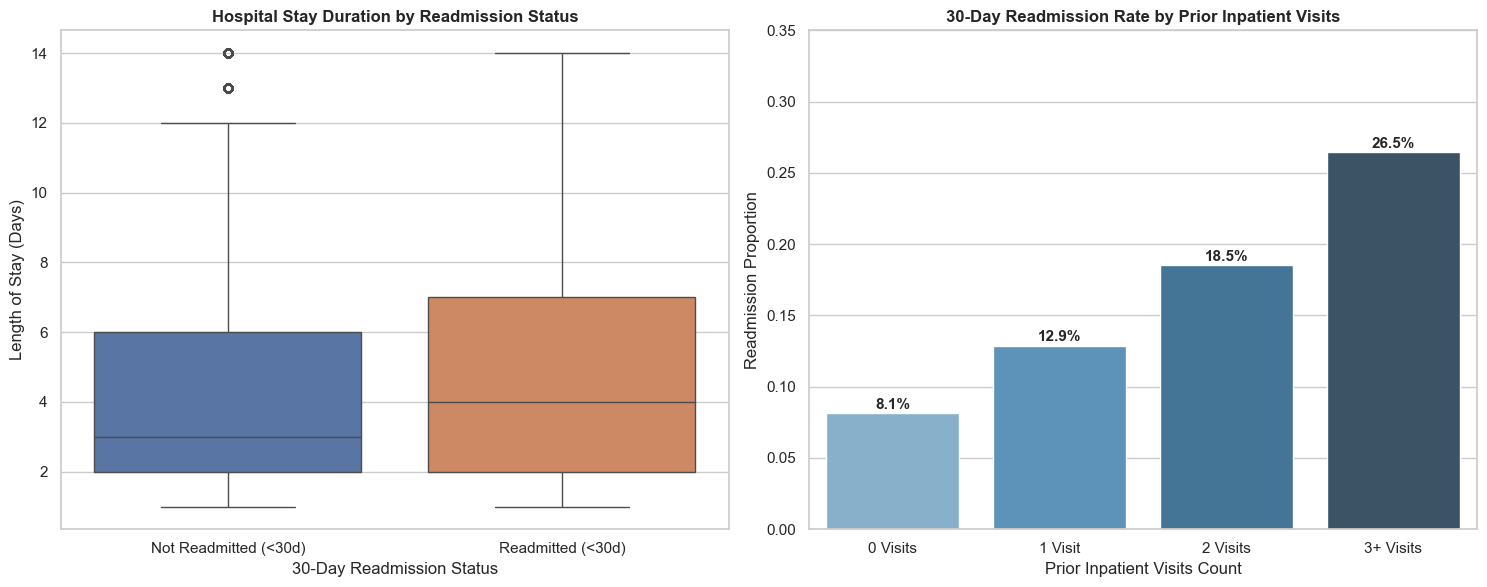

Visualizations saved successfully to 'docs/visualizations/eda_summary_plots.png'.


In [8]:
import os
os.makedirs('../docs/visualizations', exist_ok=True)

# Set figure canvas
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Length of Stay Distribution (Box Plot)
sns.boxplot(
    data=df, 
    x='readmitted_30', 
    y='time_in_hospital', 
    hue='readmitted_30',
    legend=False,
    ax=axes[0], 
    palette=['#4C72B0', '#DD8452']
)
axes[0].set_title('Hospital Stay Duration by Readmission Status', fontsize=12, fontweight='bold')
axes[0].set_xlabel('30-Day Readmission Status')
axes[0].set_ylabel('Length of Stay (Days)')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Not Readmitted (<30d)', 'Readmitted (<30d)'])

# Plot 2: Readmission Rate by Prior Inpatient Visit Bins (Bar Chart)
df['inpatient_bins'] = pd.cut(
    df['number_inpatient'], 
    bins=[-1, 0, 1, 2, 100], 
    labels=['0 Visits', '1 Visit', '2 Visits', '3+ Visits']
)
inpatient_rates = df.groupby('inpatient_bins', observed=False)['readmitted_30'].mean().reset_index()

sns.barplot(
    data=inpatient_rates, 
    x='inpatient_bins', 
    y='readmitted_30', 
    hue='inpatient_bins',
    legend=False,
    ax=axes[1], 
    palette='Blues_d'
)
axes[1].set_title('30-Day Readmission Rate by Prior Inpatient Visits', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prior Inpatient Visits Count')
axes[1].set_ylabel('Readmission Proportion')
axes[1].set_ylim(0, 0.35)

# Add percentage labels above bars
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(
        f"{height:.1%}", 
        (p.get_x() + p.get_width() / 2., height), 
        ha='center', va='center', xytext=(0, 6), 
        textcoords='offset points', fontweight='bold'
    )

plt.tight_layout()

# Save visuals
plt.savefig('../docs/visualizations/eda_summary_plots.png', dpi=300)
plt.show()

print("Visualizations saved successfully to 'docs/visualizations/eda_summary_plots.png'.")

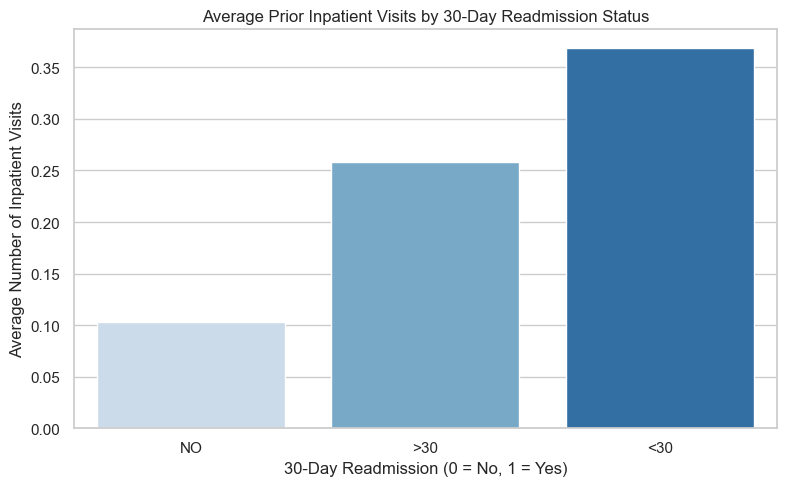

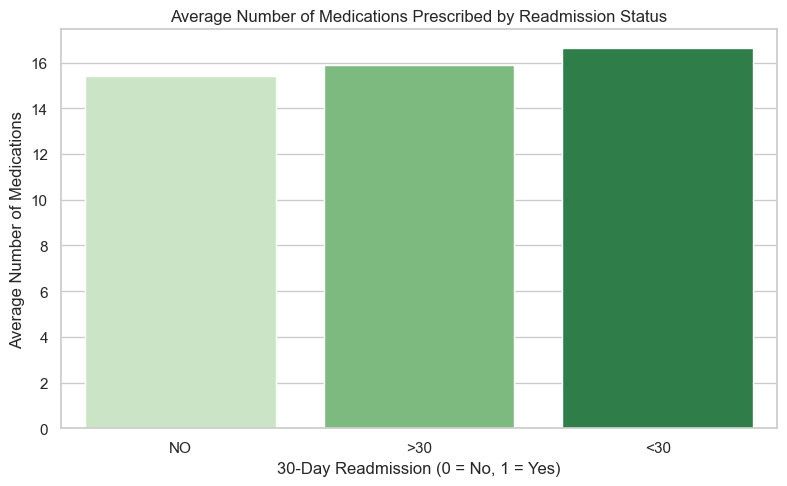

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Bar Plot: Prior Inpatient Visits vs Readmission
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df, 
    x='readmitted', 
    y='number_inpatient', 
    hue='readmitted', 
    errorbar=None, 
    palette='Blues', 
    legend=False
)
plt.title('Average Prior Inpatient Visits by 30-Day Readmission Status')
plt.xlabel('30-Day Readmission (0 = No, 1 = Yes)')
plt.ylabel('Average Number of Inpatient Visits')
plt.tight_layout()
plt.savefig('../docs/visualizations/utilization_vs_readmit.png', dpi=300)
plt.show()

# Bar Plot: Number of Medications vs Readmission
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df, 
    x='readmitted', 
    y='num_medications', 
    hue='readmitted', 
    errorbar=None, 
    palette='Greens', 
    legend=False
)
plt.title('Average Number of Medications Prescribed by Readmission Status')
plt.xlabel('30-Day Readmission (0 = No, 1 = Yes)')
plt.ylabel('Average Number of Medications')
plt.tight_layout()
plt.savefig('../docs/visualizations/age_medication_distribution.png', dpi=300)
plt.show()

## 6. Preparation Summary

This Exploratory Data Analysis notebook establishes several key empirical insights:

* **Hospital Stay Duration:** Patients readmitted within 30 days had a higher mean length of stay (4.79 days vs. 4.22 days) and a higher median (4.0 vs. 3.0 days) compared to non-readmitted patients.
* **Prior Inpatient Utilization:** Prior inpatient admission history is the strongest single predictor of early readmission. Patients with 0 prior inpatient visits exhibit an 8.2% readmission rate, whereas patients with 3 or more visits experience a 26.4% readmission rate—over triple the risk.
* **Target Distribution:** The overall baseline early readmission rate across the deduplicated dataset is 8.9%, confirming class imbalance that will require balanced weighting during machine learning model training.

## Next Step
With descriptive statistics and EDA completed, the next phase is Hypothesis Testing to mathematically confirm feature relationships.

Proceed directly to the next notebook:

👉 **[Notebook 03: Hypothesis Testing](03_hypothesis_testing.ipynb)**

## Acknowledgements and Credits
**Data Source:** UCI Machine Learning Repository — Diabetes 130-US Hospitals Dataset.

**Visualization Stack:** Built using Matplotlib and Seaborn visualization suites in Python.

## Sources and Layout Inspiration
**Code Institute Assessment Framework:** Formatted to satisfy LO1 and LO3 analytical standards.

## Tooling and Assistance

* **Development Environment:** Visual Studio Code using the Jupyter Extension for interactive data analysis and testing.
* **Core Libraries:** Python , Pandas (data manipulation), NumPy (numerical routines), Matplotlib, and Seaborn (data visualization).
* **Development & Refinement Notes:**
  * **Visualization Formatting:** I wrote and implemented the plotting scripts independently. Gemini provided minor guidance to resolve deprecation warnings in Seaborn (such as `hue` parameter warnings) and to ensure proper axis tick alignment.
  * **Language & Storytelling:** I authored all project insights, analytical interpretations, and markdown descriptions. AI was used purely as a sounding board to refine sentence flow and ensure professional presentation while maintaining full personal ownership over the text.